# 01 — Preprocessing & Train/Val/Test Split

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_colwidth', 150)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1.1 Shared Result Tracking (persists across kernel restarts)

In [2]:
import os
import pandas as pd

TUNING_LOG_PATH = 'tuning_log.csv'
FINAL_RESULTS_PATH = 'final_results.csv'

# Reload anything already saved from a previous kernel session, so results
# accumulate across restarts instead of resetting every time.
if os.path.exists(TUNING_LOG_PATH):
    tuning_log = pd.read_csv(TUNING_LOG_PATH).to_dict('records')
    print(f'Reloaded {len(tuning_log)} existing tuning_log rows from {TUNING_LOG_PATH}')
else:
    tuning_log = []

if os.path.exists(FINAL_RESULTS_PATH):
    final_results = pd.read_csv(FINAL_RESULTS_PATH).to_dict('records')
    print(f'Reloaded {len(final_results)} existing final_results rows from {FINAL_RESULTS_PATH}')
else:
    final_results = []


def log_run(model_name, config, val_acc, val_f1):
    """Record one hyperparameter run's validation metrics, print it, and persist immediately."""
    tuning_log.append({'model': model_name, 'config': str(config), 'val_accuracy': val_acc, 'val_f1_macro': val_f1})
    print(f"{model_name:22s} {str(config):55s} val_acc={val_acc:.4f}  val_f1_macro={val_f1:.4f}")
    pd.DataFrame(tuning_log).to_csv(TUNING_LOG_PATH, index=False)


def record_final_result(model_name, test_acc, f1_macro, f1_weighted):
    """Record one model's final test-set metrics and persist immediately."""
    # Overwrite any earlier entry for the same model name (e.g. re-running a section) rather than duplicating it.
    global final_results
    final_results = [r for r in final_results if r['model'] != model_name]
    final_results.append({'model': model_name, 'test_accuracy': test_acc, 'test_f1_macro': f1_macro, 'test_f1_weighted': f1_weighted})
    pd.DataFrame(final_results).to_csv(FINAL_RESULTS_PATH, index=False)


def best_config_row(df, model_name):
    """Given the tuning_log as a DataFrame, return the row with the best validation macro-F1 for one model."""
    sub = df[df['model'] == model_name]
    return sub.loc[sub['val_f1_macro'].idxmax()]

import hashlib
import ast

SAVED_MODELS_DIR = 'saved_models'
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'classical'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'rnn'), exist_ok=True)
os.makedirs(os.path.join(SAVED_MODELS_DIR, 'bert'), exist_ok=True)


def _config_hash(config):
    """Short, deterministic filename-safe hash of a hyperparameter config dict."""
    return hashlib.md5(str(config).encode()).hexdigest()[:10]


def classical_model_path(model_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'classical', f'{model_name}__{_config_hash(config)}.joblib')


def rnn_model_path(arch_name, config):
    return os.path.join(SAVED_MODELS_DIR, 'rnn', f'{arch_name}__{_config_hash(config)}.keras')


def bert_model_path(config):
    return os.path.join(SAVED_MODELS_DIR, 'bert', _config_hash(config))


def parse_config(config_str):
    """Turn the 'config' string stored in tuning_log back into a real dict, e.g. to
    reconstruct a saved-model path from a row of tuning_log_df / best_config_row()."""
    return ast.literal_eval(config_str)

## 2. Load & Inspect the Data

In [3]:
df = pd.read_csv('arXiv_scientific_dataset.csv')

In [4]:
df.head(10)

,id,title,category,category_code,published_date,updated_date,authors,first_author,summary,summary_word_count
0,cs-9308101v1,Dynamic Backtracking,Artificial Intelligence,cs.AI,8/1/93,8/1/93,['M. L. Ginsberg'],'M. L. Ginsberg',"Because of their occasional need to return to shallow points in a search\ntree, existing backtracking methods can sometimes erase meaningful progr...",79
1,cs-9308102v1,A Market-Oriented Programming Environment and its Application to\n Distributed Multicommodity Flow Problems,Artificial Intelligence,cs.AI,8/1/93,8/1/93,['M. P. Wellman'],'M. P. Wellman',Market price systems constitute a well-understood class of mechanisms that\nunder certain conditions provide effective decentralization of decisio...,119
2,cs-9309101v1,An Empirical Analysis of Search in GSAT,Artificial Intelligence,cs.AI,9/1/93,9/1/93,"['I. P. Gent', 'T. Walsh']",'I. P. Gent',"We describe an extensive study of search in GSAT, an approximation procedure\nfor propositional satisfiability. GSAT performs greedy hill-climbing...",167
3,cs-9311101v1,The Difficulties of Learning Logic Programs with Cut,Artificial Intelligence,cs.AI,11/1/93,11/1/93,"['F. Bergadano', 'D. Gunetti', 'U. Trinchero']",'F. Bergadano',"As real logic programmers normally use cut (!), an effective learning\nprocedure for logic programs should be able to deal with it. Because the cu...",174
4,cs-9311102v1,Software Agents: Completing Patterns and Constructing User Interfaces,Artificial Intelligence,cs.AI,11/1/93,11/1/93,"['J. C. Schlimmer', 'L. A. Hermens']",'J. C. Schlimmer',"To support the goal of allowing users to record and retrieve information,\nthis paper describes an interactive note-taking system for pen-based co...",187
5,cs-9312101v1,Decidable Reasoning in Terminological Knowledge Representation Systems,Artificial Intelligence,cs.AI,12/1/93,12/1/93,"['M. Buchheit', 'F. M. Donini', 'A. Schaerf']",'M. Buchheit',Terminological knowledge representation systems (TKRSs) are tools for\ndesigning and using knowledge bases that make use of terminological languag...,161
6,cs-9401101v1,Teleo-Reactive Programs for Agent Control,Artificial Intelligence,cs.AI,1/1/94,1/1/94,['N. Nilsson'],'N. Nilsson',A formalism is presented for computing and organizing actions for autonomous\nagents in dynamic environments. We introduce the notion of teleo-rea...,144
7,cs-9402101v1,Learning the Past Tense of English Verbs: The Symbolic Pattern\n Associator vs. Connectionist Models,Artificial Intelligence,cs.AI,2/1/94,2/1/94,['C. X. Ling'],'C. X. Ling',"Learning the past tense of English verbs - a seemingly minor aspect of\nlanguage acquisition - has generated heated debates since 1986, and has be...",132
8,cs-9402102v1,Substructure Discovery Using Minimum Description Length and Background\n Knowledge,Artificial Intelligence,cs.AI,2/1/94,2/1/94,"['D. J. Cook', 'L. B. Holder']",'D. J. Cook',The ability to identify interesting and repetitive substructures is an\nessential component to discovering knowledge in structural data. We descri...,194
9,cs-9402103v1,Bias-Driven Revision of Logical Domain Theories,Artificial Intelligence,cs.AI,2/1/94,2/1/94,"['M. Koppel', 'R. Feldman', 'A. M. Segre']",'M. Koppel',The theory revision problem is the problem of how best to go about revising a\ndeficient domain theory using information contained in examples tha...,130


In [5]:
print(f"Number of Rows: {df.shape[0]}")
print(f"Number of Columns: {df.shape[1]}")

Number of Rows: 287421
Number of Columns: 10


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 287421 entries, 0 to 287420
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   id                  287421 non-null  str  
 1   title               287421 non-null  str  
 2   category            287421 non-null  str  
 3   category_code       287421 non-null  str  
 4   published_date      287421 non-null  str  
 5   updated_date        287421 non-null  str  
 6   authors             287421 non-null  str  
 7   first_author        287421 non-null  str  
 8   summary             287421 non-null  str  
 9   summary_word_count  287421 non-null  int64
dtypes: int64(1), str(9)
memory usage: 427.4 MB


## 3. Missing Values & Duplicates

In [7]:
df.isnull().sum()

id                    0
title                 0
category              0
category_code         0
published_date        0
updated_date          0
authors               0
first_author          0
summary               0
summary_word_count    0
dtype: int64

In [8]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate titles:', df['title'].duplicated().sum())
print('Duplicate summaries:', df['summary'].duplicated().sum())

Duplicate rows: 0
Duplicate titles: 115
Duplicate summaries: 64


## 4. Class Distribution & Target Class Selection

In [9]:
df['category'].value_counts().head(15)

category
Machine Learning                                          80452
Computer Vision and Pattern Recognition                   71106
Computation and Language (Natural Language Processing)    37251
Artificial Intelligence                                   28726
Machine Learning (Statistics)                             13892
Neural and Evolutionary Computing                          6715
Robotics                                                   5254
Cryptography and Security                                  4376
Image and Video Processing                                 2771
Information Retrieval                                      2712
Software Engineering                                       2575
Computers and Society                                      2293
Human-Computer Interaction                                 2184
Sound                                                      1733
Methodology (Statistics)                                   1616
Name: count, dtype: int64

In [10]:
top_classes = [
    'Machine Learning',
    'Computer Vision and Pattern Recognition',
    'Computation and Language (Natural Language Processing)',
    'Artificial Intelligence',
    'Machine Learning (Statistics)',
    'Neural and Evolutionary Computing'
]

data = df[df['category'].isin(top_classes)].copy()
data = data.reset_index(drop=True)
data.shape

(238142, 10)

## 5. Exploratory Data Analysis

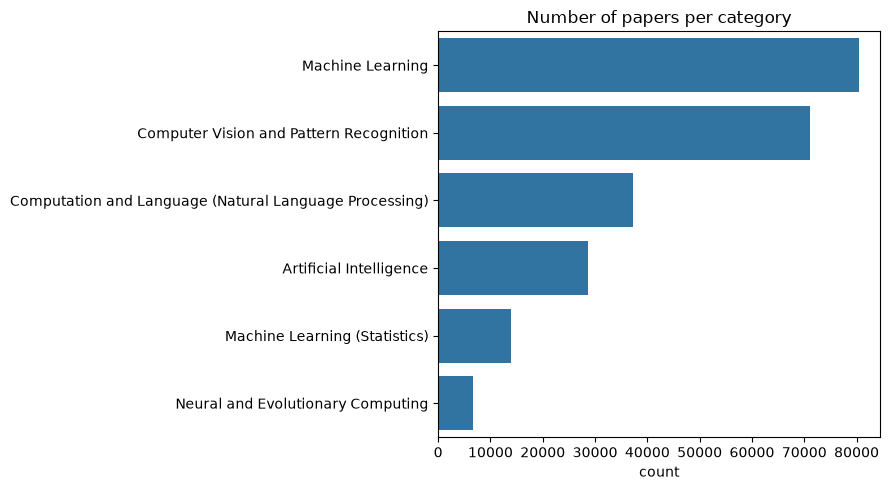

In [11]:
plt.figure(figsize=(9,5))
order = data['category'].value_counts().index
sns.countplot(data=data, y='category', order=order)
plt.title('Number of papers per category')
plt.xlabel('count')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [12]:
data['summary_word_count'].describe()

count    238142.000000
mean        170.120281
std          45.467549
min           1.000000
25%         140.000000
50%         170.000000
75%         200.000000
max         552.000000
Name: summary_word_count, dtype: float64

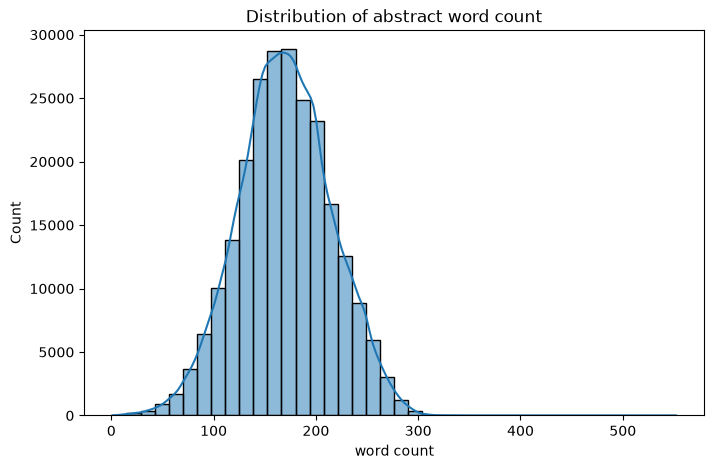

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(data['summary_word_count'], bins=40, kde=True)
plt.title('Distribution of abstract word count')
plt.xlabel('word count')
plt.show()

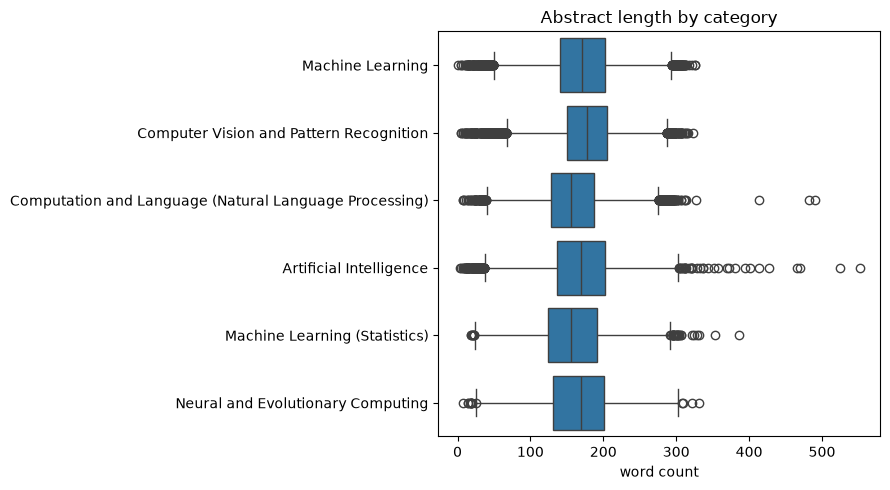

In [14]:
plt.figure(figsize=(9,5))
sns.boxplot(data=data, x='summary_word_count', y='category', order=order)
plt.title('Abstract length by category')
plt.xlabel('word count')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [15]:
print('duplicate summaries in the filtered data:', data['summary'].duplicated().sum())
data = data.drop_duplicates(subset='summary').reset_index(drop=True)
data.shape

duplicate summaries in the filtered data: 58


(238084, 10)

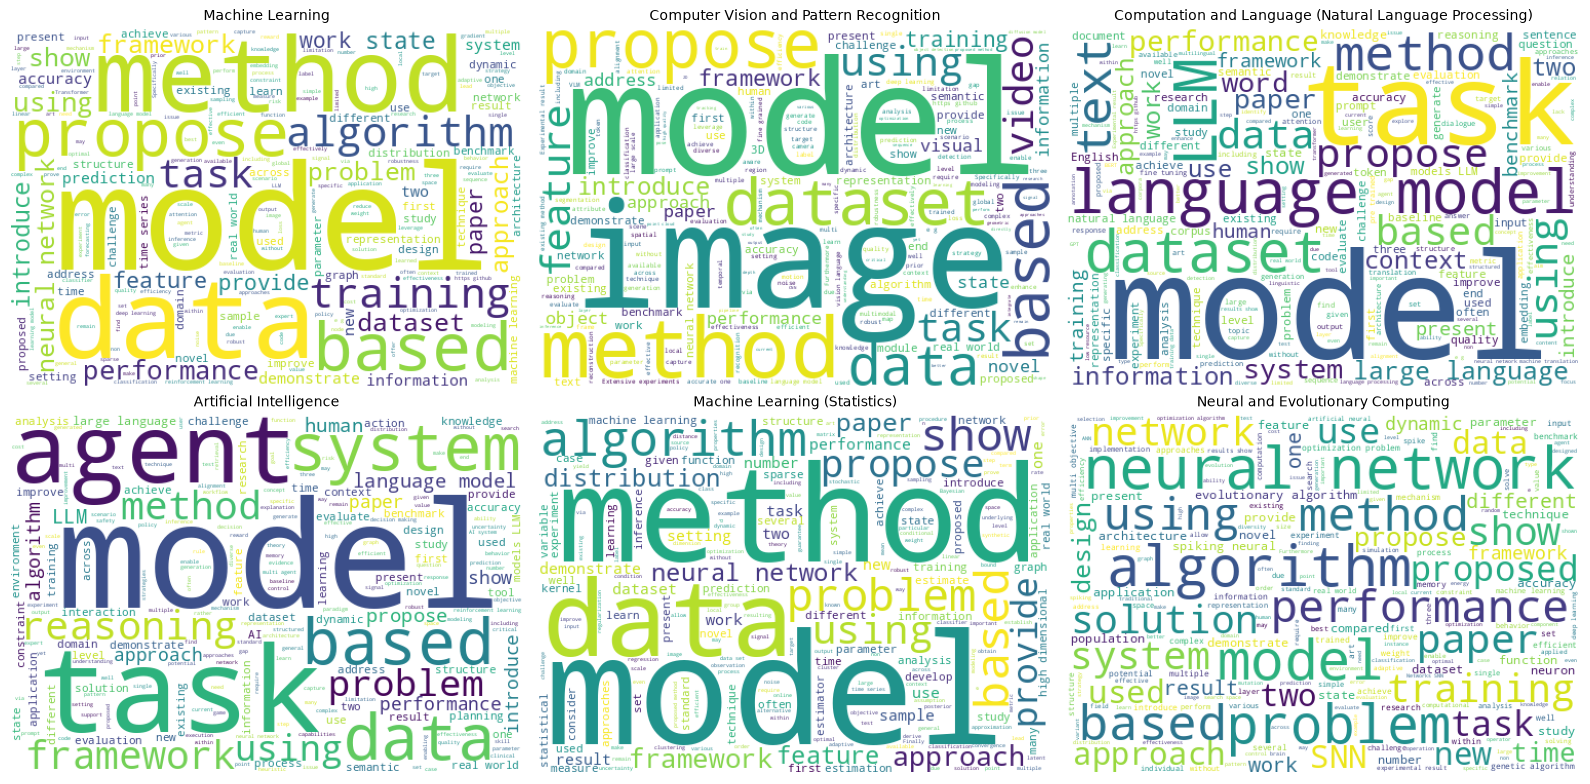

In [16]:
from wordcloud import WordCloud

fig, axes = plt.subplots(2, 3, figsize=(16,8))
axes = axes.flatten()

for ax, cat in zip(axes, top_classes):
    text = ' '.join(data[data['category'] == cat]['summary'].sample(min(2000, (data['category']==cat).sum()), random_state=RANDOM_STATE))
    wc = WordCloud(width=500, height=350, background_color='white', stopwords=None).generate(text)
    ax.imshow(wc)
    ax.set_title(cat, fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Text Cleaning

In [17]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.tokenize import word_tokenize

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

[nltk_data] Downloading package stopwords to
[nltk_data]     /home/halululu/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /home/halululu/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/halululu/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /home/halululu/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [18]:
def basic_clean(text):
    text = text.replace('\n', ' ')
    text = re.sub(r'\$.*?\$', ' ', text)      # strip inline LaTeX math ($...$)
    text = re.sub(r'\\[a-zA-Z]+', ' ', text)   # strip LaTeX commands (\alpha, \frac, ...)
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)       # drop digits & punctuation
    text = re.sub(r'\s+', ' ', text).strip()
    return text

sample = data['summary'].iloc[1]
print('Prev:\n', sample[:300])
print('\nCurrent:\n', basic_clean(sample)[:300])

Prev:
 Market price systems constitute a well-understood class of mechanisms that
under certain conditions provide effective decentralization of decision making
with minimal communication overhead. In a market-oriented programming approach
to distributed problem solving, we derive the activities and resour

Current:
 market price systems constitute a well understood class of mechanisms that under certain conditions provide effective decentralization of decision making with minimal communication overhead in a market oriented programming approach to distributed problem solving we derive the activities and resource


**Design decisions worth calling out in the report:**

In [19]:
def clean_no_stopwords_lemma(text):
    text = basic_clean(text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

def clean_keep_stopwords_lemma(text):
    text = basic_clean(text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if len(w) > 2]
    return ' '.join(tokens)

def clean_no_stopwords_stem(text):
    text = basic_clean(text)
    tokens = word_tokenize(text)
    tokens = [stemmer.stem(w) for w in tokens if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

In [20]:
sample_df = data.sample(2000, random_state=RANDOM_STATE)

v1 = sample_df['summary'].apply(clean_no_stopwords_lemma)
v2 = sample_df['summary'].apply(clean_keep_stopwords_lemma)
v3 = sample_df['summary'].apply(clean_no_stopwords_stem)

def vocab_size(series):
    words = set()
    for t in series:
        words.update(t.split())
    return len(words)

def avg_len(series):
    return series.apply(lambda t: len(t.split())).mean()

print('no stopwords + lemmatize   -> vocab:', vocab_size(v1), ' avg words/doc:', round(avg_len(v1),1))
print('keep stopwords + lemmatize -> vocab:', vocab_size(v2), ' avg words/doc:', round(avg_len(v2),1))
print('no stopwords + stemming    -> vocab:', vocab_size(v3), ' avg words/doc:', round(avg_len(v3),1))

no stopwords + lemmatize   -> vocab: 12668  avg words/doc: 115.2
keep stopwords + lemmatize -> vocab: 12761  avg words/doc: 146.8
no stopwords + stemming    -> vocab: 8854  avg words/doc: 115.2


In [21]:
print(sample_df['summary'].iloc[0][:250], '\n')
print('no stopwords + lemma :', v1.iloc[0][:250], '\n')
print('keep stopwords       :', v2.iloc[0][:250], '\n')
print('no stopwords + stem  :', v3.iloc[0][:250])

Language models pre-trained on general text have achieved impressive results
in diverse fields. Yet, the distinct linguistic characteristics of
task-oriented dialogues (TOD) compared to general text limit the practical
utility of existing language mo 

no stopwords + lemma : language model pre trained general text achieved impressive result diverse field yet distinct linguistic characteristic task oriented dialogue tod compared general text limit practical utility existing language model current task oriented dialogue pr 

keep stopwords       : language model pre trained general text have achieved impressive result diverse field yet the distinct linguistic characteristic task oriented dialogue tod compared general text limit the practical utility existing language model current task oriente 

no stopwords + stem  : languag model pre train gener text achiev impress result divers field yet distinct linguist characterist task orient dialogu tod compar gener text limit practic util exist 

## 7. Apply Final Cleaning & Post-Cleaning QA

In [22]:
data['clean_summary'] = data['summary'].apply(clean_no_stopwords_lemma)
data[['summary', 'clean_summary']].head()

,summary,clean_summary
0,"Because of their occasional need to return to shallow points in a search\ntree, existing backtracking methods can sometimes erase meaningful progr...",occasional need return shallow point search tree existing backtracking method sometimes erase meaningful progress toward solving search problem pa...
1,Market price systems constitute a well-understood class of mechanisms that\nunder certain conditions provide effective decentralization of decisio...,market price system constitute well understood class mechanism certain condition provide effective decentralization decision making minimal commun...
2,"We describe an extensive study of search in GSAT, an approximation procedure\nfor propositional satisfiability. GSAT performs greedy hill-climbing...",describe extensive study search gsat approximation procedure propositional satisfiability gsat performs greedy hill climbing number satisfied clau...
3,"As real logic programmers normally use cut (!), an effective learning\nprocedure for logic programs should be able to deal with it. Because the cu...",real logic programmer normally use cut effective learning procedure logic program able deal cut predicate procedural meaning clause containing cut...
4,"To support the goal of allowing users to record and retrieve information,\nthis paper describes an interactive note-taking system for pen-based co...",support goal allowing user record retrieve information paper describes interactive note taking system pen based computer two distinctive feature f...


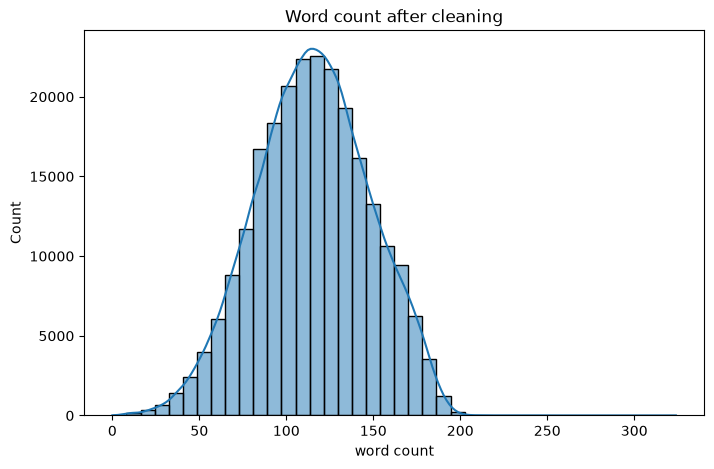

count    238084.000000
mean        115.236761
std          32.694840
min           0.000000
25%          93.000000
50%         115.000000
75%         138.000000
max         324.000000
Name: clean_word_count, dtype: float64

In [23]:
data['clean_word_count'] = data['clean_summary'].apply(lambda t: len(t.split()))

plt.figure(figsize=(8,5))
sns.histplot(data['clean_word_count'], bins=40, kde=True)
plt.title('Word count after cleaning')
plt.xlabel('word count')
plt.show()

data['clean_word_count'].describe()

In [24]:
# Explicit, order-independent check (don't rely on .describe() min alone)
n_empty = int((data['clean_word_count'] == 0).sum())
print('rows that became empty after cleaning:', n_empty)

data = data[data['clean_word_count'] > 0].reset_index(drop=True)
print('shape after removing empty-after-cleaning rows:', data.shape)

rows that became empty after cleaning: 1
shape after removing empty-after-cleaning rows: (238083, 12)


In [25]:
MIN_TOKENS = 10
short_count = int((data['clean_word_count'] < MIN_TOKENS).sum())
print(f'abstracts with fewer than {MIN_TOKENS} tokens after cleaning:', short_count)

data = data[data['clean_word_count'] >= MIN_TOKENS].reset_index(drop=True)
print('final shape after short-document filter:', data.shape)

abstracts with fewer than 10 tokens after cleaning: 71
final shape after short-document filter: (238012, 12)


## 8. Class Distribution After Cleaning & Imbalance Handling

In [26]:
data['category'].value_counts()

category
Machine Learning                                          80413
Computer Vision and Pattern Recognition                   71081
Computation and Language (Natural Language Processing)    37243
Artificial Intelligence                                   28679
Machine Learning (Statistics)                             13886
Neural and Evolutionary Computing                          6710
Name: count, dtype: int64

In [27]:
CAP = 12000  # cap per class; tune down further if training time is still too long on your GPU

parts = []
for cat, g in data.groupby('category'):
    parts.append(g.sample(n=min(len(g), CAP), random_state=RANDOM_STATE))

data_capped = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print('Before capping:')
print(data['category'].value_counts())
print('\nAfter capping (CAP =', CAP, '):')
print(data_capped['category'].value_counts())
print('\nImbalance ratio before:', round(data['category'].value_counts().max() / data['category'].value_counts().min(), 2))
print('Imbalance ratio after :', round(data_capped['category'].value_counts().max() / data_capped['category'].value_counts().min(), 2))

Before capping:
category
Machine Learning                                          80413
Computer Vision and Pattern Recognition                   71081
Computation and Language (Natural Language Processing)    37243
Artificial Intelligence                                   28679
Machine Learning (Statistics)                             13886
Neural and Evolutionary Computing                          6710
Name: count, dtype: int64

After capping (CAP = 12000 ):
category
Machine Learning                                          12000
Computer Vision and Pattern Recognition                   12000
Machine Learning (Statistics)                             12000
Artificial Intelligence                                   12000
Computation and Language (Natural Language Processing)    12000
Neural and Evolutionary Computing                          6710
Name: count, dtype: int64

Imbalance ratio before: 11.98
Imbalance ratio after : 1.79


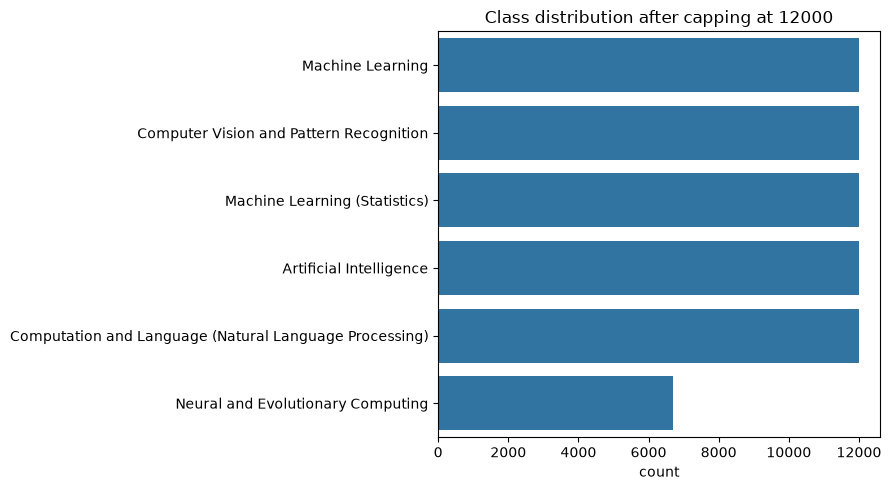

In [28]:
plt.figure(figsize=(9,5))
sns.countplot(data=data_capped, y='category', order=data_capped['category'].value_counts().index)
plt.title(f'Class distribution after capping at {CAP}')
plt.xlabel('count')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 9. Save Cleaned Data

In [29]:
data.to_csv('arxiv_cleaned_full.csv', index=False)
data_capped.to_csv('arxiv_cleaned_capped.csv', index=False)
print('saved full cleaned set:', data.shape)
print('saved capped modeling set:', data_capped.shape)

saved full cleaned set: (238012, 12)
saved capped modeling set: (66710, 12)


## 10. Train / Validation / Test Split


In [30]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    data_capped, test_size=0.30, stratify=data_capped['category'], random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['category'], random_state=RANDOM_STATE
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('train:', train_df.shape, ' val:', val_df.shape, ' test:', test_df.shape)
print('\ntrain class distribution:\n', train_df['category'].value_counts(normalize=True).round(3))

train: (46697, 12)  val: (10006, 12)  test: (10007, 12)

train class distribution:
 category
Artificial Intelligence                                   0.180
Computation and Language (Natural Language Processing)    0.180
Computer Vision and Pattern Recognition                   0.180
Machine Learning                                          0.180
Machine Learning (Statistics)                             0.180
Neural and Evolutionary Computing                         0.101
Name: proportion, dtype: float64


In [31]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df['category'])
y_val = label_encoder.transform(val_df['category'])
y_test = label_encoder.transform(test_df['category'])

num_classes = len(label_encoder.classes_)
print('classes:', list(label_encoder.classes_))
print('num_classes:', num_classes)

classes: ['Artificial Intelligence', 'Computation and Language (Natural Language Processing)', 'Computer Vision and Pattern Recognition', 'Machine Learning', 'Machine Learning (Statistics)', 'Neural and Evolutionary Computing']
num_classes: 6


In [32]:
from sklearn.utils.class_weight import compute_class_weight

class_weight_values = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: w for i, w in enumerate(class_weight_values)}
print('class weights (used to counter residual imbalance during training):')
for i, cls in enumerate(label_encoder.classes_):
    print(f'  {cls:60s} -> {class_weight_dict[i]:.3f}')

class weights (used to counter residual imbalance during training):
  Artificial Intelligence                                      -> 0.927
  Computation and Language (Natural Language Processing)       -> 0.927
  Computer Vision and Pattern Recognition                      -> 0.927
  Machine Learning                                             -> 0.927
  Machine Learning (Statistics)                                -> 0.927
  Neural and Evolutionary Computing                            -> 1.657


## Handoff to Notebook 2/3/4

In [33]:
import joblib

train_df.to_csv('train_df.csv', index=False)
val_df.to_csv('val_df.csv', index=False)
test_df.to_csv('test_df.csv', index=False)

joblib.dump(label_encoder, 'label_encoder.joblib')
joblib.dump(class_weight_dict, 'class_weight_dict.joblib')

print('Saved train_df, val_df, test_df, label_encoder, class_weight_dict.')
print('You can now close this kernel and open 02_classical_ml.ipynb, 03_rnn_family.ipynb, and/or 04_bert.ipynb independently.')

Saved train_df, val_df, test_df, label_encoder, class_weight_dict.
You can now close this kernel and open 02_classical_ml.ipynb, 03_rnn_family.ipynb, and/or 04_bert.ipynb independently.
